# Laboratorio 4 — Detección de fraude mediante regresión logística

Objetivo: clasificar transacciones legítimas (`isFraud=0`) y fraudulentas (`isFraud=1`) usando `scikit-learn`. Se analiza el desbalance de clases y se evalúa el desempeño con **precision, recall, F1, PR-AUC, ROC-AUC y matriz de confusión**.

El CSV proviene del bucket público de AWS S3 indicado en el laboratorio. Para facilitar la ejecución en equipos personales, se toma una muestra reproducible del 10% de cada bloque de lectura. **Las métricas corresponden a esa muestra, no a los 6,362,620 registros completos.**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             accuracy_score, precision_score, recall_score, f1_score,
                             average_precision_score, roc_auc_score, PrecisionRecallDisplay)

RANDOM_STATE = 42
pd.set_option('display.max_columns', 30)

## 1. Carga de datos

Se excluyen los identificadores `nameOrig` y `nameDest` para evitar un volumen excesivo de memoria y usar variables interpretables. Se mantienen los montos, saldos, paso temporal, tipo de transacción y bandera preexistente.

In [2]:
url = 'https://hybridge-education-machine-learning-datasets.s3.us-east-1.amazonaws.com/Fraud.csv'
columnas = ['step', 'type', 'amount', 'oldbalanceOrg', 'newbalanceOrig',
            'oldbalanceDest', 'newbalanceDest', 'isFraud', 'isFlaggedFraud']
tipos = {'step': 'int16', 'type': 'category', 'amount': 'float32',
         'oldbalanceOrg': 'float32', 'newbalanceOrig': 'float32',
         'oldbalanceDest': 'float32', 'newbalanceDest': 'float32',
         'isFraud': 'int8', 'isFlaggedFraud': 'int8'}

# Leer en bloques reduce memoria; el muestreo mantiene aproximadamente la prevalencia real.
bloques = pd.read_csv(url, usecols=columnas, dtype=tipos, chunksize=250_000)
df = pd.concat([bloque.sample(frac=0.10, random_state=RANDOM_STATE) for bloque in bloques],
               ignore_index=True)
print(f'Registros de la muestra: {len(df):,}')
display(df.head())

Registros de la muestra: 636,262


,step,type,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,9,CASH_OUT,479828.781250,0.0,0.000000e+00,6.863438e+05,1166172.625,0,0
1,9,CASH_IN,129065.257812,4794364.0,4.923429e+06,2.788678e+06,4889687.500,0,0
2,3,CASH_IN,381371.281250,6152391.0,6.533762e+06,1.303189e+06,921817.625,0,0
3,11,PAYMENT,24504.869141,1371.0,0.000000e+00,0.000000e+00,0.000,0,0
4,12,CASH_IN,423914.531250,65161.0,4.890755e+05,1.512519e+06,1436293.375,0,0


## 2. Exploración y calidad

En detección de fraude, la exactitud (accuracy) puede resultar engañosa cuando los fraudes representan una fracción pequeña del total.

In [3]:
display(df.info())
print('\nValores faltantes por columna:')
print(df.isna().sum())
print('\nDuplicados:', df.duplicated().sum())
print('\nDistribución de la variable objetivo:')
print(df['isFraud'].value_counts().rename(index={0:'Legítima', 1:'Fraude'}))
print(f"Porcentaje de fraude: {df['isFraud'].mean():.4%}")
print('\nFraude por tipo de transacción:')
display(pd.crosstab(df['type'], df['isFraud'], normalize='index').rename(columns={0:'Legítima',1:'Fraude'}))

<class 'pandas.DataFrame'>
RangeIndex: 636262 entries, 0 to 636261
Data columns (total 9 columns):
 #   Column          Non-Null Count   Dtype   
---  ------          --------------   -----   
 0   step            636262 non-null  int16   
 1   type            636262 non-null  category
 2   amount          636262 non-null  float32 
 3   oldbalanceOrg   636262 non-null  float32 
 4   newbalanceOrig  636262 non-null  float32 
 5   oldbalanceDest  636262 non-null  float32 
 6   newbalanceDest  636262 non-null  float32 
 7   isFraud         636262 non-null  int8    
 8   isFlaggedFraud  636262 non-null  int8    
dtypes: category(1), float32(5), int16(1), int8(2)
memory usage: 15.2 MB


None


Valores faltantes por columna:
step              0
type              0
amount            0
oldbalanceOrg     0
newbalanceOrig    0
oldbalanceDest    0
newbalanceDest    0
isFraud           0
isFlaggedFraud    0
dtype: int64

Duplicados: 4

Distribución de la variable objetivo:
isFraud
Legítima    635434
Fraude         828
Name: count, dtype: int64
Porcentaje de fraude: 0.1301%

Fraude por tipo de transacción:


isFraud,Legítima,Fraude
type,,
CASH_IN,1.000000,0.000000
CASH_OUT,0.998032,0.001968
DEBIT,1.000000,0.000000
PAYMENT,1.000000,0.000000
TRANSFER,0.992706,0.007294


## 3. Variables y separación entrenamiento/prueba

La división es estratificada (80% entrenamiento, 20% prueba), de modo que ambas particiones conservan aproximadamente la proporción de fraudes. Se ajusta el escalado únicamente con entrenamiento para evitar fuga de información.

In [4]:
X = df.drop(columns=['isFraud'])
y = df['isFraud'].astype(int)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print('Entrenamiento:', X_train.shape, '| Prueba:', X_test.shape)
print('Fraudes en entrenamiento:', int(y_train.sum()), '| Fraudes en prueba:', int(y_test.sum()))

Entrenamiento: (509009, 8) | Prueba: (127253, 8)
Fraudes en entrenamiento: 662 | Fraudes en prueba: 166


## 4. Preprocesamiento y entrenamiento

Las variables numéricas se estandarizan. `type` se convierte a variables binarias mediante one-hot encoding. `class_weight='balanced'` penaliza más los errores sobre la clase minoritaria. El modelo usa una tubería (`Pipeline`) para evitar fuga de datos.

In [5]:
numericas = X.select_dtypes(include=np.number).columns.tolist()
categoricas = ['type']
preprocesamiento = ColumnTransformer([
    ('numericas', StandardScaler(), numericas),
    ('tipo', OneHotEncoder(handle_unknown='ignore'), categoricas)
])
modelo = Pipeline([
    ('preprocesamiento', preprocesamiento),
    ('clasificador', LogisticRegression(max_iter=1000, class_weight='balanced',
                                       solver='lbfgs', random_state=RANDOM_STATE))
])
modelo.fit(X_train, y_train)
print('Modelo entrenado correctamente.')

Modelo entrenado correctamente.


## 5. Evaluación final del modelo

La clase positiva es `1` (fraude). **Recall** mide cuántos fraudes se detectan; **precision** mide qué proporción de las alertas realmente son fraudes. F1 equilibra ambas. PR-AUC es especialmente útil con clases desbalanceadas.

**Esta es la celda que debe aparecer en la captura de pantalla de la entrega, una vez ejecutado el notebook.**

In [6]:
y_pred = modelo.predict(X_test)
y_prob = modelo.predict_proba(X_test)[:, 1]

metricas = pd.DataFrame({
    'Métrica': ['Accuracy', 'Precision (fraude)', 'Recall (fraude)', 'F1 (fraude)', 'PR-AUC', 'ROC-AUC'],
    'Valor': [accuracy_score(y_test, y_pred), precision_score(y_test, y_pred, zero_division=0),
              recall_score(y_test, y_pred, zero_division=0), f1_score(y_test, y_pred, zero_division=0),
              average_precision_score(y_test, y_prob), roc_auc_score(y_test, y_prob)]
})
print('=== EVALUACIÓN FINAL: REGRESIÓN LOGÍSTICA ===')
print(metricas.to_string(index=False, formatters={'Valor': '{:.4f}'.format}))
print('\nReporte de clasificación:')
print(classification_report(y_test, y_pred, target_names=['Legítima', 'Fraude'], zero_division=0))
print('Matriz de confusión [filas: real; columnas: predicción]:')
print(confusion_matrix(y_test, y_pred))

=== EVALUACIÓN FINAL: REGRESIÓN LOGÍSTICA ===
           Métrica  Valor
          Accuracy 0.9457
Precision (fraude) 0.0232
   Recall (fraude) 0.9880
       F1 (fraude) 0.0453
            PR-AUC 0.6161
           ROC-AUC 0.9920

Reporte de clasificación:
              precision    recall  f1-score   support

    Legítima       1.00      0.95      0.97    127087
      Fraude       0.02      0.99      0.05       166

    accuracy                           0.95    127253
   macro avg       0.51      0.97      0.51    127253
weighted avg       1.00      0.95      0.97    127253

Matriz de confusión [filas: real; columnas: predicción]:
[[120174   6913]
 [     2    164]]


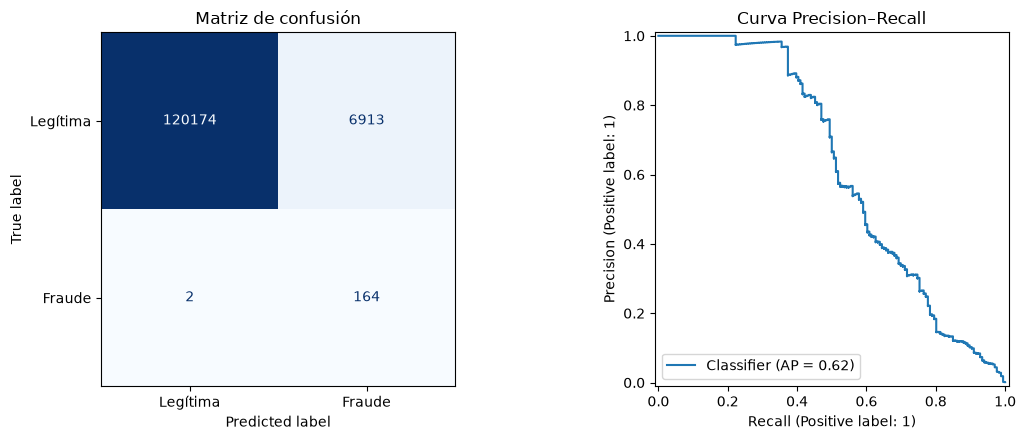

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred,
    display_labels=['Legítima', 'Fraude'], cmap='Blues', ax=axes[0], colorbar=False)
axes[0].set_title('Matriz de confusión')
PrecisionRecallDisplay.from_predictions(y_test, y_prob, ax=axes[1])
axes[1].set_title('Curva Precision–Recall')
plt.tight_layout()
plt.show()

## 6. Interpretación y conclusiones

- El criterio principal es **recall de fraude**, sin perder de vista precision y falsas alarmas.
- Un umbral de 0.5 no tiene por qué ser el más adecuado para un sistema antifraude: el costo de omitir un fraude puede superar el costo de investigar una operación legítima.
- Las métricas no están precalculadas: se generan al ejecutar las celdas con el CSV real.
- Limitaciones: se usa una muestra del 10%, los tipos categóricos se simplifican y no se hace una validación temporal ni un ajuste de umbral. Antes de producción se debería evaluar en datos futuros, calibrar probabilidades y medir costos de falsos positivos.